In [1]:
title = "# Probabilities: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import itertools
import scipy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Probabilities: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

## Overview

Both exercises below are classic probability puzzles that are notorious for being unintuitive at first glance. For each one, you will:

1. Work out the probability **analytically**, using the definition of conditional probability and/or Bayes' theorem.
2. Check your answer with a **Monte-Carlo simulation**.

Getting the same answer from both directions is a good way to build confidence that you understand *why* the result holds, not just that you can reproduce a formula.

---
## Exercise 0: Warm-up — dice, sets, and Bayes' theorem

Before the two main exercises, a few short questions to refresh the concepts from the lecture: sample spaces, independence, and Bayes' theorem. These are quick — a couple of lines of code or algebra each.

1. Two fair six-sided dice are rolled. Enumerate the sample space $\Omega$ of the 36 equally-likely $(d_1, d_2)$ outcomes (e.g. with `itertools.product`), and use it to compute $\Pr(\text{sum} = 7)$.
2. Let $A$ be "the sum is 7" and $B$ be "at least one die shows a 4". Are $A$ and $B$ independent? Check using $\Pr(A \mid B) \overset{?}{=} \Pr(A)$.
3. A rare disease affects 0.1% of the population. A test for it is 99% accurate on people who have it, and gives a false positive 2% of the time on people who don't. Using Bayes' theorem, what is $\Pr(\text{disease} \mid \text{positive test})$?

> **Hint.** For question 3: $\Pr(D \mid {+}) = \dfrac{\Pr(+ \mid D)\Pr(D)}{\Pr(+ \mid D)\Pr(D) + \Pr(+ \mid D^c)\Pr(D^c)}$ — the denominator is the law of total probability applied to $\{D, D^c\}$. The answer is smaller than most people expect; that's the point.


In [5]:
# Your code here: work through questions 1-3 above

# 1. 
x = list(itertools.product([1,2,3,4,5,6], repeat=2));

subset_seven = set()

for t in x:
    if sum(t)==7:
        subset_seven.add(t);

print(len(subset_seven)/len(x))

#2. 
subset_four = set()

for t in x:
    if t[0]==4 or t[1]==4:
        subset_four.add(t)

subset_four_given_seven = set()

for t in subset_seven:
    if t[0]==4 or t[1]==4:
        subset_four_given_seven.add(t)

print(len(subset_four_given_seven)/len(subset_seven)) #Not the same as result of 1.


0.16666666666666666
0.3333333333333333


---
## Exercise 1: The birthday problem

**Question.** What is the probability that at least two people in this room share a birthday?

More precisely: let $B_n$ be the event that at least two people out of $n$ share a birthday. Find $\Pr(B_n)$.

**Assumptions:**
- Birthdays are independent between people.
- Every day of the year is equally likely to be someone's birthday.
- The year has 365 days (ignore leap years).

### Task

1. It is easier to work with the complementary event $B_n^c$ (no two people share a birthday). Write $\Pr(B_n)$ in terms of $\Pr(B_n^c)$.
2. Introduce the birthday $d_i$ of person $i$, and use independence to write $\Pr(B_n^c)$ as a product of terms, one per person, that each ask "what is the probability this person's birthday differs from everyone before them?"
3. Simplify your product to a closed-form expression for $\Pr(B_n^c)$, and hence for $\Pr(B_n)$.
4. Evaluate $\Pr(B_n)$ for $n = 17$ and $n = 23$. Which of these two group sizes gives roughly even odds?
5. Make a plot of $\Pr(B_n)$ as a function of $n$, for $n$ from 1 to 60. At what $n$ does the room "feel" like a coin flip?

> **Hint.** For step 3, `math.factorial` will overflow or lose precision once $n$ gets large. Consider computing the product directly with `numpy` (e.g. via `np.prod` or `np.cumprod`), or working in log-space with `scipy.special.gammaln`, instead of forming $365!$ explicitly.

> **Bonus.** How does the answer change on a planet where the year has a different number of days? Turn your expression for $\Pr(B_n)$ into a function of both $n$ and the number of days in the year, and see how the "50% group size" scales.

#### Your analytic derivation

*(Write your derivation of $\Pr(B_n)$ here, e.g. using LaTeX in this markdown cell.)*

In [ ]:
# Your code here: implement Pr(B_n) and evaluate it for n = 17 and n = 23
Pr(A & B) = Pr(A)Pr(B), assuming independence. Nobody has the same birthday means the available number of days to choose from reduces with every
person, so Pr(A & B & C...) means the first person has any of the 365 days available, the second can choose out of 364 ans so on. 
We get 365/365 - 364/365 - ... = 365!/(365-n)!365^n

0.31500766529656066
0.5072972343239854


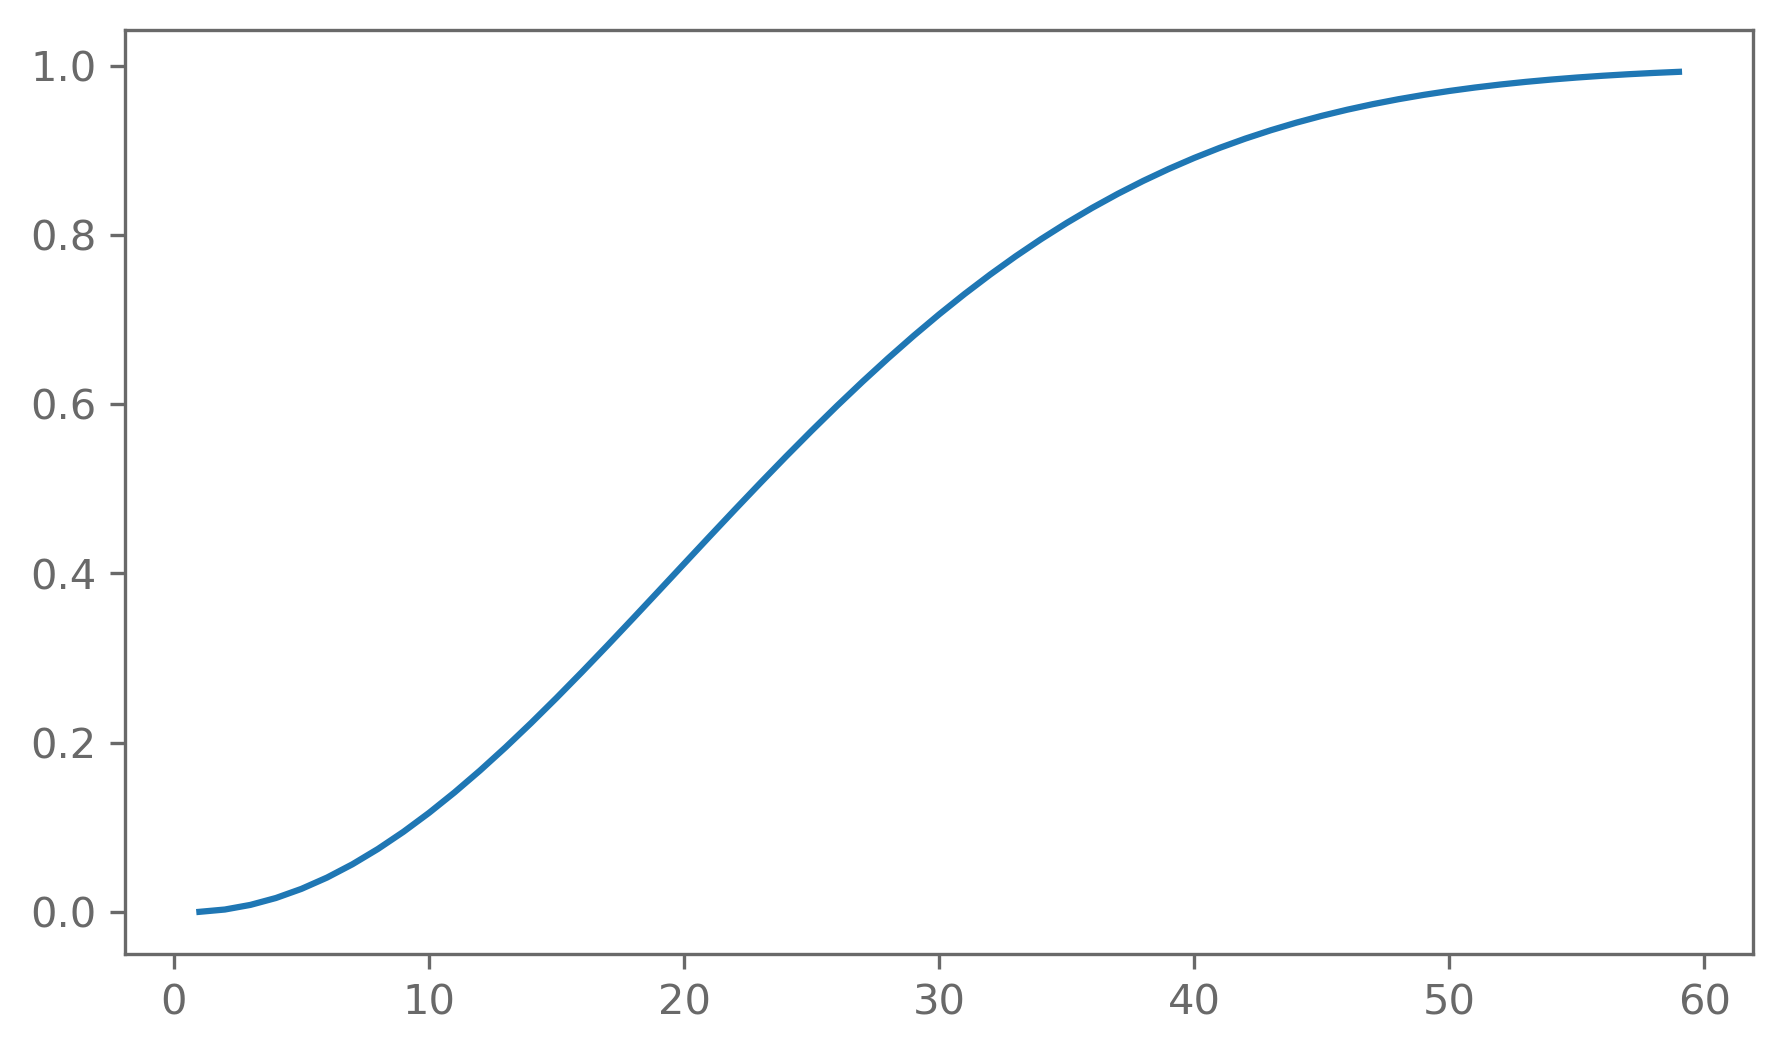

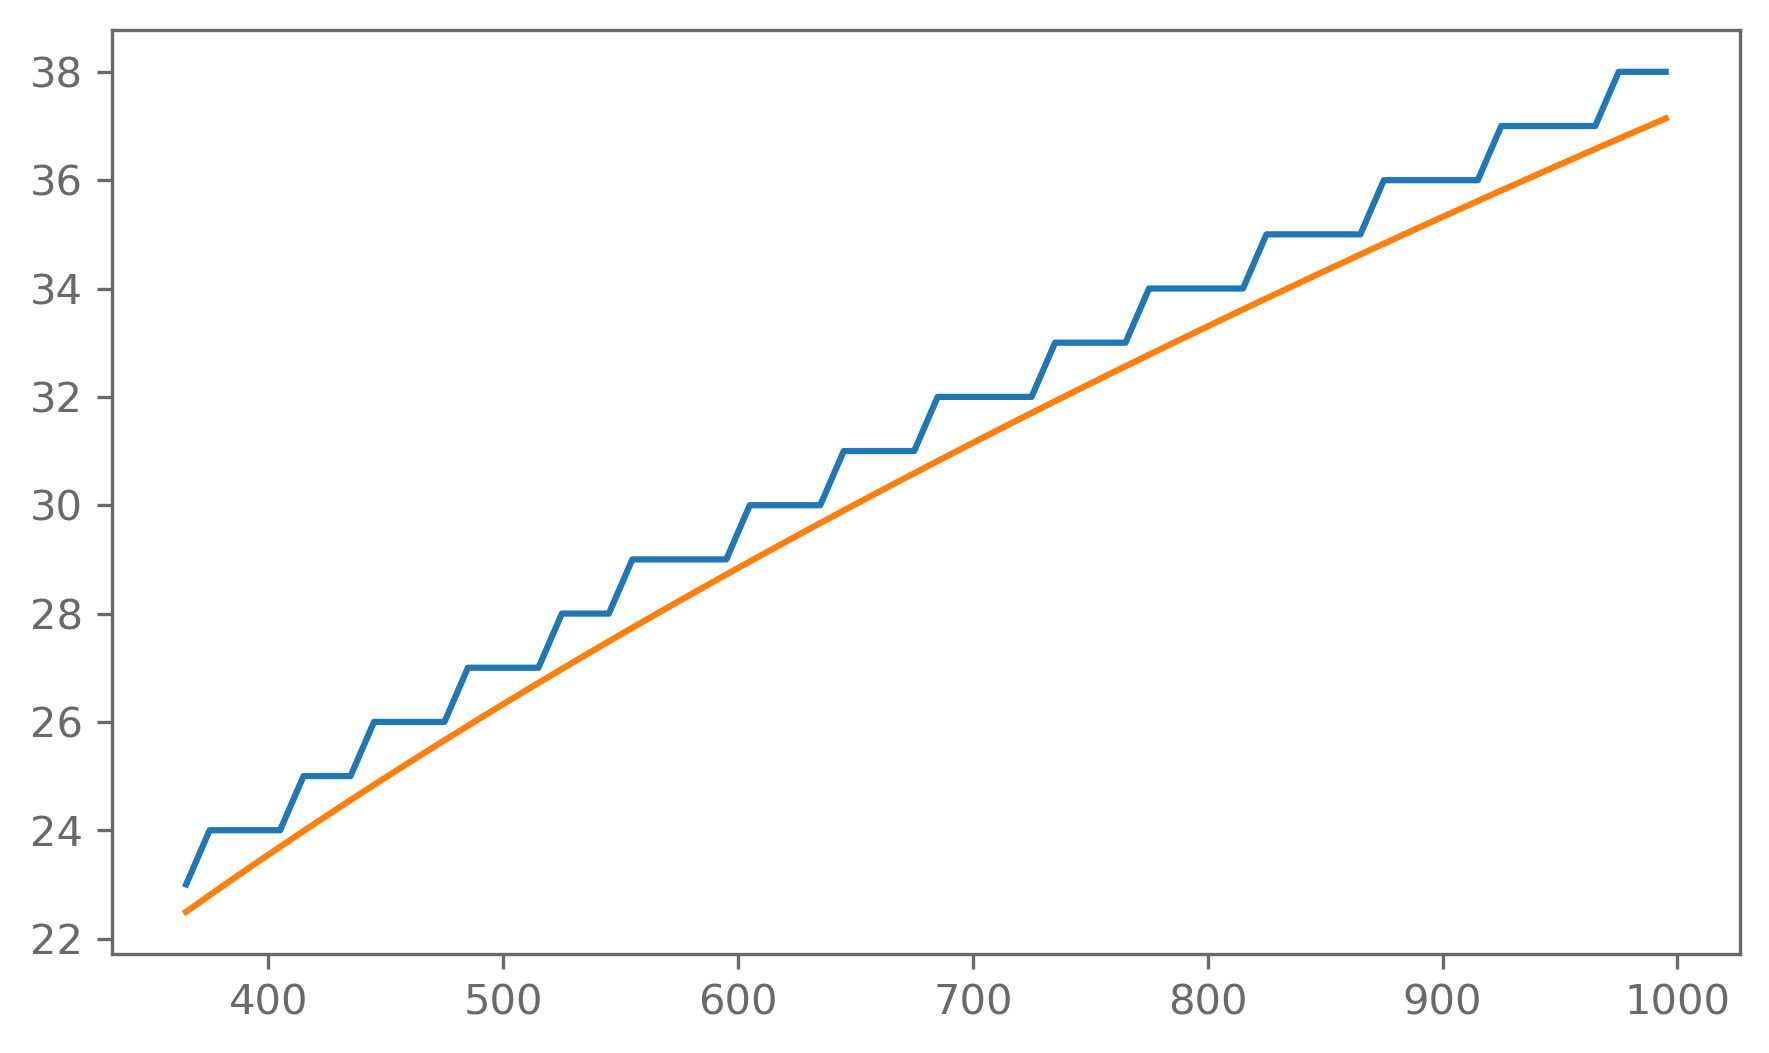

In [11]:
# Your code here: plot Pr(B_n) as a function of n

def f(k,n): 
    return (1 - scipy.special.perm(k,n)/(k**n));

print(f(365,17))
print(f(365,23))

f_0 = list()
N_0 = np.arange(1,60,1)

for n in N_0:
    f_0.append(f(365.0,n));
    
plt.plot(N_0,f_0)
plt.show()

f_1=list();
d_1 = np.arange(365.0,1000.0,10.0);
N_1 = list();

for k in d_1:
    n = 23.0;
    x = f(k,n);
    while x < 0.5:
        n = n+1.0;
        x = f(k,n);
        
    f_1.append(x)
    N_1.append(n)

plt.plot(d_1,N_1)
plt.plot(d_1,1.1774*np.sqrt(d_1))

---
## Exercise 2: The Monty Hall problem

**Setup.** In a game show, a contestant is presented with three doors. Behind one door is a car, and behind the other two are goats. The goal is to win the car.

The game proceeds as follows:
1. The contestant chooses a door, which stays closed for now.
2. The host, who knows where the car is, opens one of the *other two* doors, always revealing a goat.
3. The contestant may now **stick** with their original door, or **switch** to the remaining closed door.

**Question.** What is the best strategy? Concretely, suppose the contestant first chooses door 1 and the host opens door 3 (revealing a goat). What is $\Pr(C_1 \mid H_3)$, the probability of winning by sticking, versus $\Pr(C_2 \mid H_3)$, the probability of winning by switching?

### Task

You are free to tackle these two parts in either order — each is a useful check on the other.

**A. Simulate the game.**
1. Write a function that plays one round: randomly place the car, have the contestant pick a door, have the host open a door with a goat behind it (excluding the contestant's door and the car's door), and record whether *sticking* or *switching* would have won.
2. Repeat for many rounds (e.g. $10^5$) and estimate $\Pr(\text{win} \mid \text{stick})$ and $\Pr(\text{win} \mid \text{switch})$ from the simulated frequencies.

**B. Derive it analytically.**
1. Write out $\Pr(C_1 \mid H_3)$ using Bayes' theorem:
$$\Pr(C_1 \mid H_3) = \frac{\Pr(H_3 \mid C_1)\,\Pr(C_1)}{\Pr(H_3)}$$
2. Work out each ingredient: the prior $\Pr(C_i)$ for each door, and the likelihood $\Pr(H_3 \mid C_i)$ for each door (i.e. how likely is the host to open door 3, given where the car actually is?).
3. Expand the denominator $\Pr(H_3)$ by summing over the three possible car locations, and put everything together.
4. Compare $\Pr(C_1 \mid H_3)$ and $\Pr(C_2 \mid H_3)$ to your simulated estimates from part A.

> **Hint.** The denominator $\Pr(H_3)$ is the same for both $\Pr(C_1\mid H_3)$ and $\Pr(C_2\mid H_3)$. If you only care about *which* strategy is better, you can sidestep computing it entirely by looking at the posterior odds $\Pr(C_2 \mid H_3) / \Pr(C_1 \mid H_3)$ instead.

> **Bonus.** How do the winning probabilities change if there are $N > 3$ doors, with the host still opening $N - 2$ goat-doors one at a time before offering the switch?

In [3]:
# Your code here: simulate the Monty Hall game and estimate
# Pr(win | stick) and Pr(win | switch)

n=0
N=100000
stick=0
switch=0

while n < N:
    n = n+1;
    car = [1,0,0];
    choice = [1,0,0];
    host = [1,0,0];
    np.random.shuffle(car);
    np.random.shuffle(choice);
    np.random.shuffle(host);
    while (host == car or host == choice):
        np.random.shuffle(host);

    #print("===")
    #print(car)
    #print(choice)
    #print(host)
    #print("===")

    if car == choice:
        stick = stick + 1;
    
    else:
        switch = switch + 1;

print("Example: ")
print(car)
print(choice)
print(host)
print("=========")

print(stick/(stick + switch))
print(switch/(stick + switch))


Example: 
[1, 0, 0]
[0, 1, 0]
[0, 0, 1]
0.33355
0.66645


#### Your analytic derivation

*(Write your derivation of $\Pr(C_1 \mid H_3)$ and $\Pr(C_2 \mid H_3)$ here.)*

In [9]:
#Probabilities depend on what door is chosen by the player, so we will choose door one in the first step. C_i denotes the door behind which the care is, while H_i dneotes the door which the host opens.
#Note that the host can never open the door with the car behind, so P(C_i|H_i)=0, nor can he open the door the player chose P(C_i|H_1) = 0.
#Bayes formula tells us Pr(C_i|H_3) = Pr(H_3|C_i)Pr(C_i)/Pr(H_3)
# Pr(C_i)=1/3 is an independent variable, since the car is placed at random before the game.
# If the car is behind door one (already chosen by the player), the host can either open door 2 or 3 so Pr(H_3|C_1) = 1/2.
# If the car is behind door 2, the host can only choose door 3 so Pr(H_3|C_2) = 1.
# So the numerator is 1/2 * 1/3 if the car is behind door 1 and 1*1/3 if the car is behind door 2.
#To calculate the denominator we expand in the possible outcomes P(H_3) = P(H_3|C_1)P(C_1) + P(H_3|C_2)P(C_2) + P(H_3|C_3)P(C_3)m= 1/2 * 1/3 + 1 * 1/3 + 0 * 1/3.
#It follows Pr(C_1|H_3)=1/3 and Pr(C_2|H_3) = 2/3 and it is always advantageous to swap doors.

# For N doors, when the host opens all but two of them, the chosen has always the probability 1/N to contain the car, while the other remaining door "sucks up"
# all remaining probabilities such that it has probability (N-1)/N to contain the car.